# Predicting the Energy Performance of French Houses

## 1. Project & Dataset Description

**Aim.** Predict the energy performance of a French house from its physical characteristics only
(surface, construction period, insulation, heating system, climate zone...), as two tasks:

- **Regression**: annual conventional primary energy consumption `conso_5_usages_par_m2_ep` (kWh/m²/year)
- **Classification**: energy label `etiquette_dpe` (7 classes, A to G)

**Dataset.** [DPE Logements existants (depuis juillet 2021)](https://data.ademe.fr/datasets/dpe03existant), ADEME,
Licence Ouverte 2.0, also on [data.gouv.fr](https://www.data.gouv.fr/datasets/dpe-logements-existants-depuis-juillet-2021).
Our fixed sample contains 80,000 house diagnostics from region 84, extracted on 2026-11-17.
It contains 42 stored fields, of which 17 are selected as model inputs. Duplicate diagnosis IDs
and known replaced diagnoses were removed during extraction; several diagnoses may still concern
the same building. The common preparation and grouped split are documented in section 5.1.

**Existing solutions.** TODO: summarise the related work listed in the team form and how we differ.

## 2. Imports

Libraries used below and their versions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

SEED = 42
np.random.seed(SEED)

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 2.2.2 | scikit-learn 1.4.2


## 3. Data Access

Chargement des 80 000 diagnostics depuis une version fixe du fichier GitHub.
L'extraction ADEME n'est nécessaire que pour créer un nouvel échantillon.

In [2]:
# !git clone https://github.com/Yannisloum63/dpe-house-energy-prediction.git
# %cd dpe-house-energy-prediction
# !python scripts/extract_dpe.py --region 84 --n 80000

In [3]:
import requests

# Version fixe du jeu de données
VERSION = "f47d6754403fc71d7a5313292785ba472571ba21"
BASE_URL = (
    "https://raw.githubusercontent.com/"
    f"Yannisloum63/dpe-house-energy-prediction/{VERSION}/data/"
)

df = pd.read_csv(
    BASE_URL + "dpe_houses.csv.gz",
    compression="gzip",
    dtype={
        "numero_dpe": "string",
        "numero_dpe_remplace": "string",
        "id_rnb": "string",
        "code_insee_ban": "string",
        "code_departement_ban": "string",
        "code_region_ban": "string",
    },
)

response = requests.get(
    BASE_URL + "dpe_houses.csv.gz.manifest.json", timeout=30
)
response.raise_for_status()
manifest = response.json()

assert len(df) == manifest["saved_rows"] == 80000
print("Dimensions :", df.shape)
df.head()

Dimensions : (80000, 42)


,numero_dpe,numero_dpe_remplace,date_etablissement_dpe,code_insee_ban,code_departement_ban,code_region_ban,coordonnee_cartographique_x_ban,coordonnee_cartographique_y_ban,surface_habitable_logement,annee_construction,...,conso_5_usages_par_m2_ep,etiquette_dpe,emission_ges_5_usages_par_m2,etiquette_ges,type_installation_chauffage_n1,type_batiment,id_rnb,version_dpe,type_installation_chauffage_n2,ventilation_posterieure_2012
0,2238E0355918R,2138E0546906I,2022-02-22,38087,38,84,839981.79,6499791.42,79.0,1948.0,...,251.6,E,10.0,B,installation individuelle,maison,83HHVD177CD4,2.0,NaN,0
1,2269E1277295L,<NA>,2022-06-10,69094,69,84,831211.13,6517579.14,138.2,1988.0,...,186.7,D,43.0,D,installation individuelle,maison,ZTAPMG7FVH7Z,2.1,NaN,0
2,2574E3225392O,<NA>,2025-10-12,74062,74,84,944421.21,6547447.15,175.0,1970.0,...,508.7,G,110.0,G,installation individuelle,maison,<NA>,2.5,NaN,0
3,2573E2135618D,<NA>,2025-06-28,73235,73,84,962533.62,6485003.01,49.6,NaN,...,398.6,F,15.0,C,installation individuelle,maison,S4Y21TCKBW1S,2.4,NaN,0
4,2426E0103928J,2426E0097882V,2024-01-11,26054,26,84,849694.89,6357000.43,125.0,1990.0,...,211.7,D,8.0,B,installation individuelle,maison,<NA>,2.3,NaN,0


### Columns that must never be model inputs

The label is the worse of the consumption class and the GHG emission class, so the computed outputs leak the targets.

In [4]:
TARGET_REG = "conso_5_usages_par_m2_ep"
TARGET_CLF = "etiquette_dpe"

# Les 17 variables retenues ; les ensembles seront chargés en section 5.1.
FEATURES = manifest["feature_columns"]
assert len(FEATURES) == 17
assert all(column in df.columns for column in FEATURES)
print("Variables d'entrée :", df[FEATURES].shape)

Variables d'entrée : (80000, 17)


## 4. Exploratory Data Analysis

Statistiques générales sur les 80 000 diagnostics ; analyse des valeurs extrêmes
sur le train uniquement (section 4.3).

### 4.1 Metadata: number of instances, features, types

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 42 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   numero_dpe                                      80000 non-null  string 
 1   numero_dpe_remplace                             7299 non-null   string 
 2   date_etablissement_dpe                          80000 non-null  object 
 3   code_insee_ban                                  80000 non-null  string 
 4   code_departement_ban                            80000 non-null  string 
 5   code_region_ban                                 80000 non-null  string 
 6   coordonnee_cartographique_x_ban                 80000 non-null  float64
 7   coordonnee_cartographique_y_ban                 80000 non-null  float64
 8   surface_habitable_logement                      80000 non-null  float64
 9   annee_construction                     

### 4.2 Missing values: identification, interpretation, chosen strategy

In [6]:
df[FEATURES].isna().mean().sort_values(
    ascending=False
).to_frame("missing_rate")

,missing_rate
isolation_toiture,0.075237
type_ventilation,0.062100
type_installation_chauffage_n1,0.036375
type_emetteur_installation_chauffage_n1,0.036375
classe_inertie_batiment,0.010212
qualite_isolation_plancher_bas,0.009000
zone_climatique,0.002350
classe_altitude,0.002350
qualite_isolation_murs,0.000013
periode_construction,0.000000


### 4.3 Examen des valeurs extrêmes dans le train

Distribution de la surface, de la hauteur sous plafond et du nombre de niveaux
dans le train, pour repérer les valeurs à vérifier.

In [7]:
import io
import hashlib
import importlib.util
from pathlib import Path

AUDIT_VERSION = "7f75336b420c5c96ca12615a85fb32bf3526664f"
AUDIT_URL = (
    "https://raw.githubusercontent.com/"
    f"Yannisloum63/dpe-house-energy-prediction/{AUDIT_VERSION}"
)
response = requests.get(AUDIT_URL + "/data/splits/assignments.csv.gz", timeout=60)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == "40fa6f625ff9351348211dfc89bcb49a32fa919b402fc095475e9f623cdf1b97"
assignments = pd.read_csv(io.BytesIO(response.content), compression="gzip", dtype="string")
assert assignments.numero_dpe.is_unique and df.numero_dpe.is_unique
assert set(assignments.numero_dpe) == set(df.numero_dpe)
train_ids = assignments.loc[assignments["split"].eq("train"), "numero_dpe"]
df_train_raw = df.set_index("numero_dpe", drop=False).loc[train_ids].reset_index(drop=True).copy()
assert len(df_train_raw) == 47974

response = requests.get(AUDIT_URL + "/scripts/inspect_outliers.py", timeout=60)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == "e1a2d2f856bd857b542b1faf7b6280345f2e61594da09c067a0849adaaaa6fb0"
audit_path = Path("inspect_outliers_shared.py")
audit_path.write_bytes(response.content)
spec = importlib.util.spec_from_file_location("inspect_outliers_shared", audit_path)
outlier_audit = importlib.util.module_from_spec(spec)
spec.loader.exec_module(outlier_audit)
print("Train brut : ", df_train_raw.shape, "— aucune valeur modifiée.")

Train brut :  (47974, 42) — aucune valeur modifiée.


In [8]:
outlier_summary = outlier_audit.summarize(df_train_raw)
display(outlier_summary)

,field,n,minimum,q01,q1,median,q3,q99,maximum,iqr,iqr_lower,iqr_upper,outside_iqr_count,iqr_warning
0,hauteur_sous_plafond,47974,1.2,2.2,2.5,2.5,2.5,3.100,282.0,0.0,2.50,2.50,17405,"IQR nul : règle dégénérée, pas de nettoyage au..."
1,nombre_niveau_logement,47974,1.0,1.0,1.0,2.0,2.0,4.000,115.0,1.0,-0.50,3.50,502,"Repérage statistique uniquement, pas une preuv..."
2,surface_habitable_logement,47974,7.0,36.0,83.7,104.2,137.4,322.027,3771.0,53.7,3.15,217.95,2319,"Repérage statistique uniquement, pas une preuv..."


Pour la hauteur, Q1 = Q3 = 2,5 m : l'IQR est nul et la règle signale
17 405 lignes, y compris des hauteurs normales.
Elle signale aussi 502 lignes pour les niveaux et 2 319 pour la surface.
Les bornes de 3,5 niveaux et de 217,95 m² ne sont pas des limites physiques :
les points hors moustaches ne sont donc pas tous à supprimer.

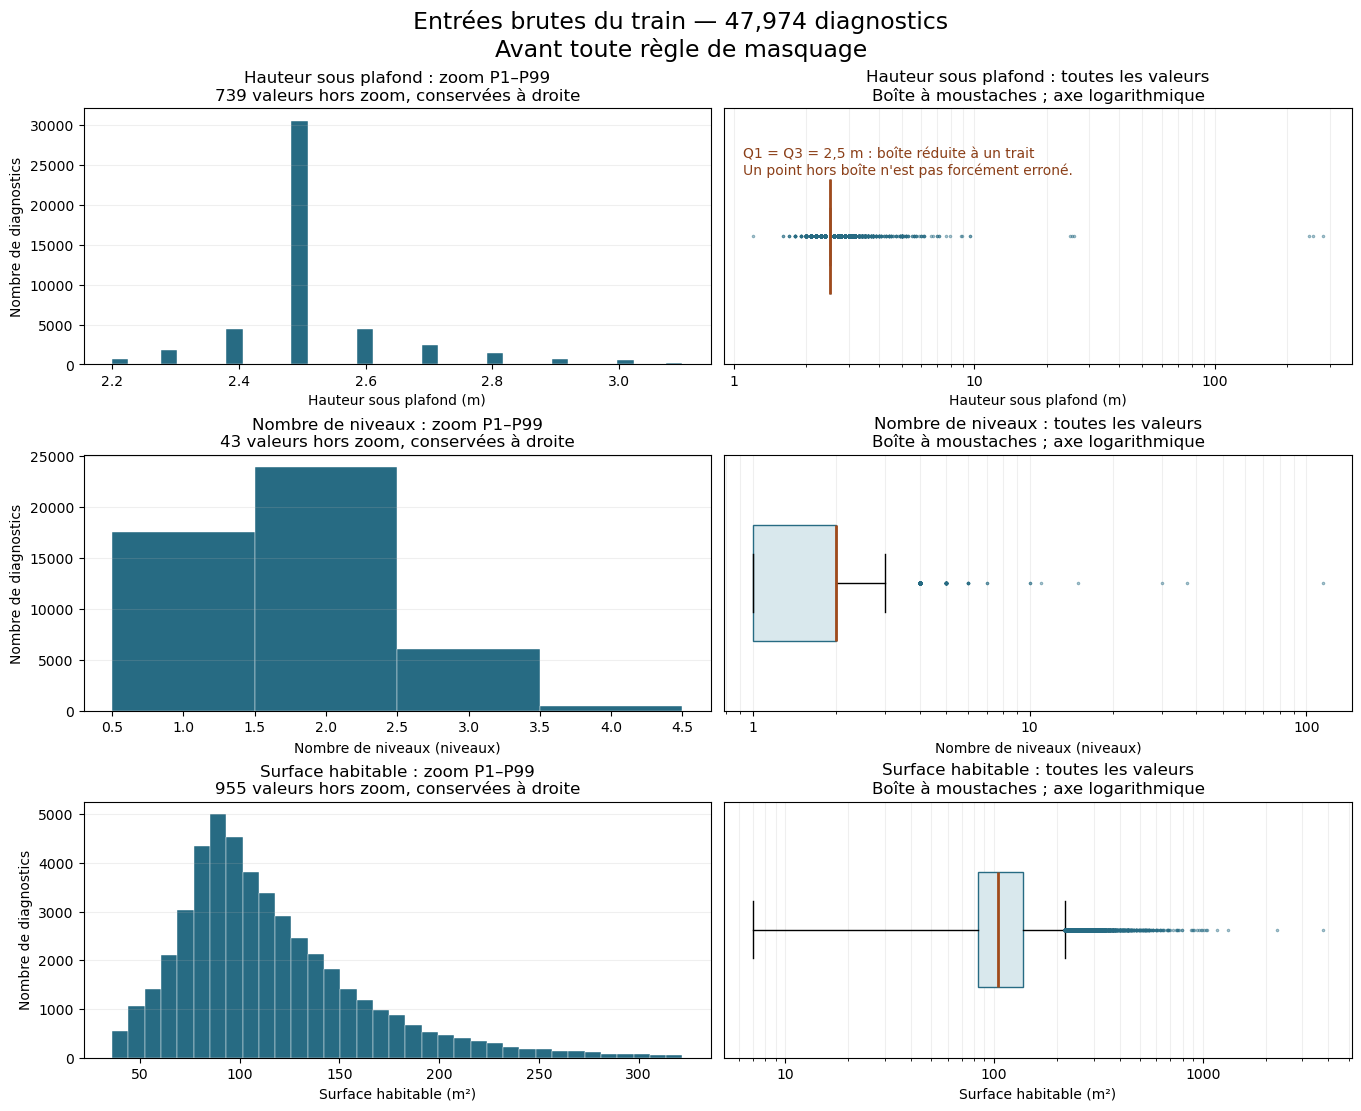

In [9]:
fig = outlier_audit.distribution_figure(df_train_raw)
plt.show()

À gauche : zoom P1–P99, avec le nombre de valeurs hors cadre.
À droite : toutes les valeurs sur un axe logarithmique.
La hauteur se concentre autour de 2,5 m ; les surfaces sont plus étalées.

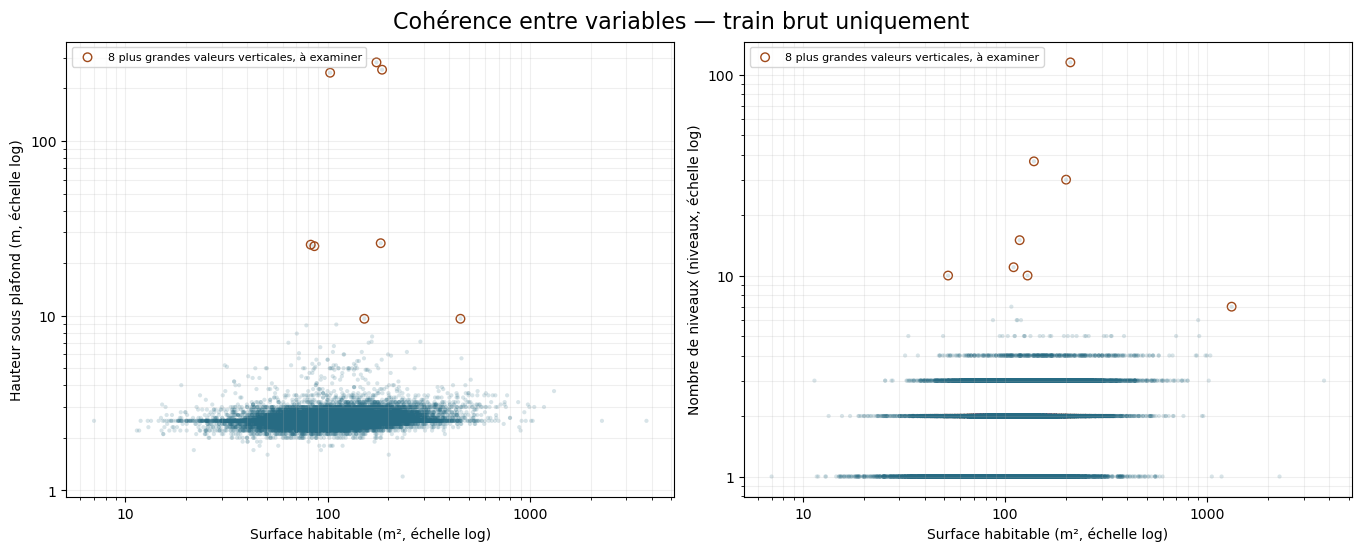

In [10]:
fig = outlier_audit.relationship_figure(df_train_raw)
plt.show()

Les cercles orange indiquent les huit plus grandes valeurs de l'axe vertical.
Des hauteurs de centaines de mètres ou des nombres de niveaux très élevés pour
une surface ordinaire suggèrent de vérifier les fiches et les unités.

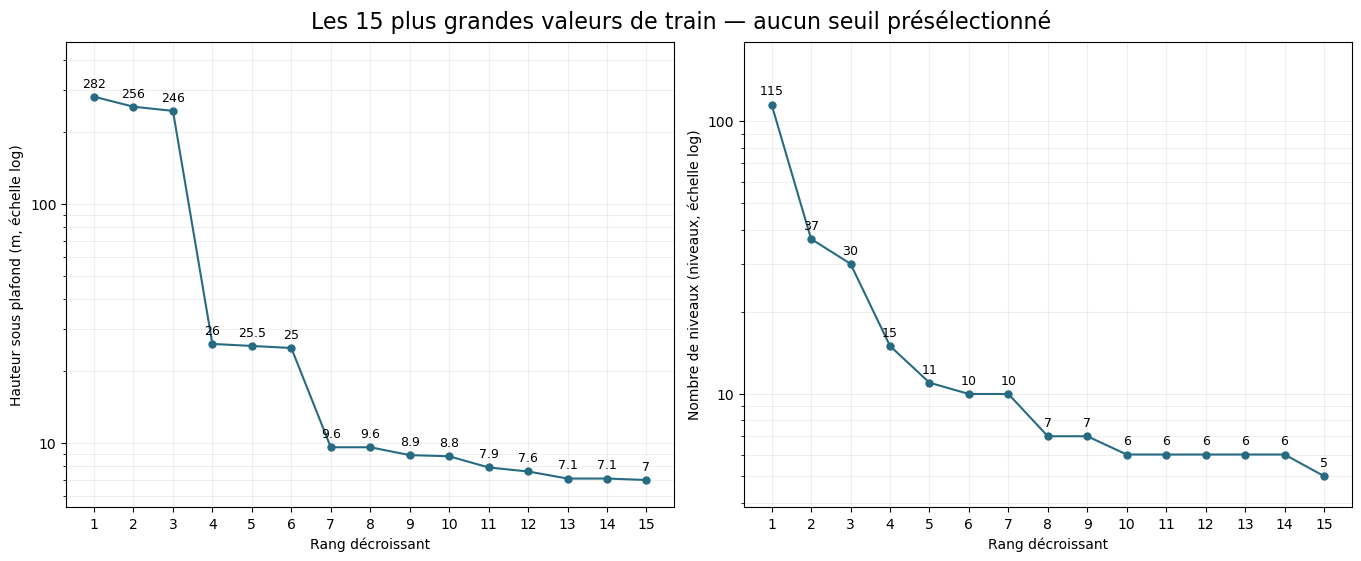

In [11]:
fig = outlier_audit.tail_figure(df_train_raw)
plt.show()

Hauteurs les plus élevées : 282, 256, 246, 26, 25,5 et 25 m, puis 9,6 m.
Une erreur d'unité ou de décimale est possible ; les petites hauteurs de 1,2–1,7 m
sont aussi à vérifier. Pour les niveaux, la proximité entre 10 et 11 ne suffit
pas à justifier une coupure à 10.

In [12]:
extreme_cases = outlier_audit.extreme_records(df_train_raw)
display(extreme_cases)

,field_examined,selection,numero_dpe,periode_construction,hauteur_sous_plafond,nombre_niveau_logement,surface_habitable_logement,version_dpe
0,hauteur_sous_plafond,largest_8,2501E1674693M,avant 1948,282.0,2.0,174.4,2.4
1,hauteur_sous_plafond,largest_8,2171E0805451Q,avant 1948,256.0,2.0,185.9,1.1
2,hauteur_sous_plafond,largest_8,2138E0566399B,2006-2012,246.0,1.0,102.9,1.0
3,hauteur_sous_plafond,largest_8,2501E2504206V,1948-1974,26.0,1.0,183.0,2.4
4,hauteur_sous_plafond,largest_8,2301E3942044F,2013-2021,25.5,2.0,82.5,2.3
5,hauteur_sous_plafond,largest_8,2642E0870902B,avant 1948,25.0,3.0,86.0,2.6
6,hauteur_sous_plafond,largest_8,2301E2322164D,avant 1948,9.6,1.0,151.9,2.2
7,hauteur_sous_plafond,largest_8,2369E0893027Y,avant 1948,9.6,1.0,453.6,2.2
8,hauteur_sous_plafond,smallest_5,2363E2599926R,avant 1948,1.2,3.0,235.0,2.3
9,hauteur_sous_plafond,smallest_5,2438E1436559W,1978-1982,1.6,1.0,50.5,2.3


Traitement : hauteurs > 10 m et niveaux > 20 remplacés par une valeur manquante
en section 5.1. Les autres valeurs sont conservées.
[Justification et fiches correspondantes](https://github.com/Yannisloum63/dpe-house-energy-prediction/blob/main/docs/outlier_review.md).

### 4.4 Target study: distribution and class balance

In [13]:
df[TARGET_CLF].value_counts(normalize=True).sort_index()

etiquette_dpe
A    0.032175
B    0.050888
C    0.217950
D    0.286050
E    0.195025
F    0.112025
G    0.105887
Name: proportion, dtype: float64

### 4.5 Correlations, feature selection, dimension reduction, anomaly detection

### 4.6 Unsupervised clustering and correlation with the targets

### 4.7 Data enrichment from other sources (INSEE, Météo-France...)

### 4.8 Interpretations, hypotheses and conclusions

## 5. Baseline & Ensemble Models

### 5.1 Données pour les modèles

Découpage fixe : **47 974 train, 16 007 validation et 16 019 test**.
Les diagnostics liés par RNB ou référence de remplacement restent ensemble.

Les cellules suivantes préparent `X_*` (17 entrées), `y_*_reg` (consommation)
et `y_*_clf` (classe A–G). Avec `apply_mask=True`, les hauteurs > 10 m et les
niveaux > 20 sont remplacés par une valeur manquante : 20 cellules au total, dont 9
dans le train. Aucune ligne n'est supprimée. Les graphiques de la section 4.3
montrent les valeurs brutes.

L'imputation, l'encodage et la standardisation restent à ajuster dans le Pipeline,
sur chaque pli d'entraînement. Utiliser `groups_train` pour la validation croisée.

[Options de chargement et limites du découpage](https://github.com/Yannisloum63/dpe-house-energy-prediction/blob/main/docs/data_preparation.md).

In [14]:
import hashlib
import importlib.util
from pathlib import Path

# Version du traitement et du découpage.
PREPARATION_VERSION = "8dde8ceb65a31e94500ff6f1965ff11794de3dc3"
PREPARATION_URL = (
    "https://raw.githubusercontent.com/"
    f"Yannisloum63/dpe-house-energy-prediction/{PREPARATION_VERSION}"
)
response = requests.get(PREPARATION_URL + "/scripts/prepare_data.py", timeout=60)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == "7913ebe910803f6bff6603f82a43fd51a0262c79f3bcae2309c91224df5ef4fc"
module_path = Path("prepare_data_shared.py")
module_path.write_bytes(response.content)
spec = importlib.util.spec_from_file_location("prepare_data_shared", module_path)
preparation = importlib.util.module_from_spec(spec)
spec.loader.exec_module(preparation)

In [15]:
df_raw, datasets, FEATURES, masked_values, preparation_report = preparation.load_shared_data(
    PREPARATION_URL, apply_mask=True
)

df_train = datasets["train"]
df_val = datasets["validation"]
df_test = datasets["test"]

display(pd.DataFrame({
    "ensemble": ["train", "validation", "test"],
    "lignes": [len(df_train), len(df_val), len(df_test)],
    "variables": [len(FEATURES)] * 3,
}))
display(masked_values.groupby("field").size().rename("valeurs_remplacees").to_frame())
print("Valeurs remplacées par NaN :", len(masked_values))
print("Groupes connus partagés :", preparation_report["cross_split_groups"])

assert len(masked_values) == preparation_report["masked_cells"] == 20
assert sum(len(frame) for frame in datasets.values()) == len(df_raw) == 80000
assert preparation_report["masking_applied"]
train_changes = masked_values[masked_values.numero_dpe.isin(df_train.numero_dpe)]
assert len(train_changes) == 9

# Vérifier que seules les cellules du journal ont changé dans le train.
expected_train = df_train_raw.set_index("numero_dpe")[FEATURES].copy()
for field, changes in train_changes.groupby("field"):
    expected_train.loc[changes.numero_dpe, field] = np.nan
pd.testing.assert_frame_equal(
    df_train.set_index("numero_dpe")[FEATURES].sort_index(),
    expected_train.sort_index(),
    check_dtype=False,
)

,ensemble,lignes,variables
0,train,47974,17
1,validation,16007,17
2,test,16019,17


,valeurs_remplacees
field,
hauteur_sous_plafond,13
nombre_niveau_logement,7


Valeurs remplacées par NaN : 20
Groupes connus partagés : 0


In [16]:
X_train = df_train[FEATURES].copy()
X_val = df_val[FEATURES].copy()
X_test = df_test[FEATURES].copy()

y_train_reg, y_val_reg, y_test_reg = (
    frame[TARGET_REG].copy() for frame in [df_train, df_val, df_test]
)
y_train_clf, y_val_clf, y_test_clf = (
    frame[TARGET_CLF].copy() for frame in [df_train, df_val, df_test]
)
groups_train = df_train["group_id"].copy()
NUMERIC_FEATURES = preparation_report["numeric_features"]
CATEGORICAL_FEATURES = preparation_report["categorical_features"]

print("Prêt pour les graphiques sur df_train et les modèles sur X_train / X_val.")

Prêt pour les graphiques sur df_train et les modèles sur X_train / X_val.


### 5.2 Preprocessing pipelines and models

### 5.3 Training and validation (nested cross-validation, learning curves)

### 5.4 Test and interpretation of results

## 6. Enhanced Models & Hyperparameter Tuning

### 6.1 Justification of choices

### 6.2 Tuning (parallel coordinates plot of the search)

### 6.3 Interpretation and analysis of the results

## 7. Conclusion and outlook